In [1]:
# 1. SETUP
import os, re, glob, warnings
import numpy as np, pandas as pd, scipy.io as sio
import matplotlib.pyplot as plt, seaborn as sns, networkx as nx
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
from scipy.stats import skew, kurtosis
import plotly.express as px
warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid")

DATA_ROOT = os.environ.get("NINAPRO_ROOT", "/kaggle/input")
FS, WIN, SEED = 2000, 400, 42          # 2000 Hz, window = 400 samples (200 ms)
rng = np.random.default_rng(SEED)
CH = [f"ch{i:02d}" for i in range(1, 13)]

In [2]:
# 2. FIND FILES
pat = re.compile(r"S(\d+)_E(\d+)_A\d+\.mat$")
paths = sorted(glob.glob(f"{DATA_ROOT}/**/S*_E*_A*.mat", recursive=True))
files = pd.DataFrame([(p, int(m[1]), int(m[2])) for p in paths if (m := pat.search(p))],
                     columns=["path", "subject", "exercise"])
assert len(files) > 0, "No .mat files found"

print(f"Files: {len(files)} | Subjects: {files.subject.nunique()} | Exercises: {sorted(files.exercise.unique().tolist())}")
print(f"12 EMG channels, {FS} Hz, window = {WIN} samples = {WIN*1000//FS} ms")

Files: 120 | Subjects: 40 | Exercises: [1, 2, 3]
12 EMG channels, 2000 Hz, window = 400 samples = 200 ms


In [3]:
# 3. LOAD EVERYTHING ONCE (one file at a time, to save memory)
samples, wins, segs, n_bad, n_total = [], [], [], 0, 0

for f in files.itertuples():
    m = sio.loadmat(f.path, variable_names=["emg", "restimulus", "rerepetition"])
    emg = m["emg"].astype(np.float32)
    lab, rep = m["restimulus"].ravel(), m["rerepetition"].ravel()
    n_bad += int((~np.isfinite(emg)).sum()); n_total += emg.size

    # 4000 random raw samples (for stats + plots)
    s = pd.DataFrame(emg[rng.choice(len(emg), min(4000, len(emg)), replace=False)], columns=CH)
    s["subject"] = f.subject 
    samples.append(s)

    # one segment = one gesture in one repetition
    cut = np.flatnonzero((np.diff(lab) != 0) | (np.diff(rep) != 0)) + 1
    for a, b in zip(np.r_[0, cut], np.r_[cut, len(lab)]):
        segs.append((f.subject, f.exercise, int(lab[a]), b - a))
        if lab[a] > 0 and b - a >= WIN:                      # active gesture -> take 1 random window
            st = rng.integers(a, b - WIN + 1)
            wins.append((f.subject, f.exercise, int(lab[a]), np.sqrt((emg[st:st+WIN] ** 2).mean(0))))  # RMS per channel

samp = pd.concat(samples, ignore_index=True)
seg = pd.DataFrame(segs, columns=["subject", "exercise", "label", "length"])
win = pd.DataFrame([w[:3] for w in wins], columns=["subject", "exercise", "label"])
rms = pd.DataFrame([w[3] for w in wins], columns=CH)        # window feature = RMS of each channel

print(f"Loaded {len(files)} files, {n_total/12:,.0f} samples per channel")
print(f"Segments: {len(seg):,} | Windows used for analysis: {len(win):,} (RMS feature, 12 channels)")

Loaded 120 files, 207,713,115 samples per channel
Segments: 23,640 | Windows used for analysis: 11,760 (RMS feature, 12 channels)


In [4]:
# 4. SPLIT SUBJECTS (train / val / test) - do this BEFORE fitting anything
subj = rng.permutation(sorted(win.subject.unique()))
n_test, n_val = max(1, round(0.2 * len(subj))), max(1, round(0.1 * len(subj)))
test, val, train = subj[:n_test], subj[n_test:n_test + n_val], subj[n_test + n_val:]
assert not set(train) & set(val) and not set(train) & set(test) and not set(val) & set(test)

is_train = win.subject.isin(train).values
print("[OK] No subject appears in two groups (no leakage)")
print(f"train: {len(train)} subjects | val: {len(val)} subjects | test: {len(test)} subjects")
print(f"windows -> train: {is_train.sum():,} | val: {win.subject.isin(val).sum():,} | test: {win.subject.isin(test).sum():,}")
print("Everything below that is 'fitted' (scaler, PCA, correlation) uses TRAIN subjects only.")

# train-only views: every statistic / plot / fitted object in A-H comes from these
split    = np.where(is_train, "train", np.where(win.subject.isin(val), "val", "test"))
samp_tr  = samp[samp.subject.isin(train)][CH]       # raw samples, train subjects
win_tr   = win[is_train]                            # window labels, train subjects
rms_tr   = rms[is_train]                            # RMS features, train subjects
seg_tr   = seg[seg.subject.isin(train)]             # segments, train subjects

[OK] No subject appears in two groups (no leakage)
train: 28 subjects | val: 4 subjects | test: 8 subjects
windows -> train: 8,232 | val: 1,176 | test: 2,352
Everything below that is 'fitted' (scaler, PCA, correlation) uses TRAIN subjects only.


In [5]:
# quick look at the structure we just described
per_subj = win.groupby("subject").size()
print(f"Subjects: {win.subject.nunique()} | windows per subject: min {per_subj.min()}, mean {per_subj.mean():.0f}, max {per_subj.max()}")
print(f"Graph per sample: {len(CH)} nodes (one per electrode), 1 feature per node (window RMS)")
display(win.assign(split=split).groupby("split").agg(subjects=("subject", "nunique"), windows=("label", "size"), gestures=("label", "nunique")))

Subjects: 40 | windows per subject: min 294, mean 294, max 294
Graph per sample: 12 nodes (one per electrode), 1 feature per node (window RMS)


,subjects,windows,gestures
split,,,
test,8,2352,49
train,28,8232,49
val,4,1176,49


#  A. Dataset summary

In [6]:
# Descriptive only (all subjects): nothing is fitted here, so no leakage.
dup = int(files.duplicated(["subject", "exercise"]).sum())
act = seg[(seg.label > 0) & (seg.length >= WIN)]
cls_all = act.groupby(["exercise", "label"]).size().rename("n").reset_index()
ratio_all = cls_all.n.max() / cls_all.n.min()
rest = seg[seg.label == 0].length.sum() / seg.length.sum() * 100

summary = pd.Series({
    "Name": "NinaPro DB2",
    "Source": "ninapro.hevs.ch (Kaggle copy)",
    "Area": "Biomedical - sEMG hand gesture recognition",
    "Samples (time steps)": f"{n_total // 12:,} per channel",
    "Windows analysed": f"{len(win):,} (200 ms each)",
    "Classes": f"{len(cls_all)} gestures (+ rest)",
    "Features": "12 channels, RMS per window (numeric, continuous)",
    "Subjects": files.subject.nunique(),
    "Class balance": f"{ratio_all:.2f}x (max/min); rest = {rest:.0f}% of samples",
    "Missing values": f"{n_bad:,}",
    "Duplicate files": dup,
}, name="value").to_frame()
display(summary)

,value
Name,NinaPro DB2
Source,ninapro.hevs.ch (Kaggle copy)
Area,Biomedical - sEMG hand gesture recognition
Samples (time steps),"207,713,115 per channel"
Windows analysed,"11,760 (200 ms each)"
Classes,49 gestures (+ rest)
Features,"12 channels, RMS per window (numeric, continuous)"
Subjects,40
Class balance,1.00x (max/min); rest = 44% of samples
Missing values,0


# B. Data quality

In [7]:
# Statistical checks on TRAIN subjects only (missing/duplicate are integrity checks on all files)
std = samp_tr.std(); near_const = std[std < 0.01 * std.median()].index.tolist()
R = rms_tr.corr()
pairs = R.where(np.triu(np.ones(R.shape), 1) > 0).stack().sort_values(ascending=False)
high_corr = pairs[pairs > 0.9]

# Calculate outliers using IQR rule
q_out = samp_tr.quantile([0.25, 0.75])
iqr_out = q_out.loc[0.75] - q_out.loc[0.25]

outlier_iqr = (
    (samp_tr < q_out.loc[0.25] - 1.5 * iqr_out) |
    (samp_tr > q_out.loc[0.75] + 1.5 * iqr_out)
).mean() * 100

print(f"Missing values     : {n_bad / n_total * 100:.4f}%", "[OK]" if n_bad == 0 else "[!]")
print(f"Duplicate files    : {dup}", "[OK]" if dup == 0 else "[!]")
print(f"Near-constant chan.: {near_const or 'none'}", "[OK]" if not near_const else "[!]")
print(f"Highly correlated  : {len(high_corr)} channel pairs with r > 0.9", "[OK]" if len(high_corr) == 0 else "[!]")
print(f"Outliers (IQR rule): {outlier_iqr.mean():.1f}% of samples")

display(pd.DataFrame({"effect on modeling": [
    "Missing values -> need imputation/removal, otherwise training breaks (NaN loss).",
    "Duplicates -> same data in train and test inflates accuracy.",
    "Near-constant channel -> gives no information, can be dropped.",
    "Highly correlated channels -> redundant information, graph edges become dense.",
    "Outliers (EMG spikes) -> can dominate scaling; use robust or per-channel normalisation."]},
    index=["Missing", "Duplicates", "Near-constant", "High correlation", "Outliers"]))

Missing values     : 0.0000% [OK]
Duplicate files    : 0 [OK]
Near-constant chan.: none [OK]
Highly correlated  : 0 channel pairs with r > 0.9 [OK]
Outliers (IQR rule): 14.2% of samples


,effect on modeling
Missing,"Missing values -> need imputation/removal, oth..."
Duplicates,Duplicates -> same data in train and test infl...
Near-constant,"Near-constant channel -> gives no information,..."
High correlation,Highly correlated channels -> redundant inform...
Outliers,Outliers (EMG spikes) -> can dominate scaling;...


# C. Statistics

In [8]:
q = samp_tr.quantile([.25, .5, .75]).T
iqr = q[0.75] - q[0.25]
outlier_iqr = ((samp_tr < q[0.25] - 1.5 * iqr) | (samp_tr > q[0.75] + 1.5 * iqr)).mean() * 100

stats = pd.DataFrame({"mean": samp_tr.mean(), "median": q[0.5], "std": samp_tr.std(), "min": samp_tr.min(), "max": samp_tr.max(),
                      "Q1": q[0.25], "Q3": q[0.75], "skew": skew(samp_tr), "kurtosis": kurtosis(samp_tr), "outlier_%": outlier_iqr})
print("Statistics of raw samples, TRAIN subjects only (these decide normalisation).")
display(stats.round(3))
print("Read it: mean ~ 0 (EMG is a signed signal). Kurtosis > 0 = heavy tails (many spikes). Skew ~ 0 = symmetric.")

Statistics of raw samples, TRAIN subjects only (these decide normalisation).


,mean,median,std,min,max,Q1,Q3,skew,kurtosis,outlier_%
ch01,-0.0,0.0,0.0,-0.006,0.006,-0.0,0.0,-0.845,894.481995,18.552
ch02,0.0,0.0,0.0,-0.006,0.006,-0.0,0.0,10.280,5342.629883,16.420
ch03,-0.0,0.0,0.0,-0.002,0.001,-0.0,0.0,-3.104,263.134003,16.700
ch04,-0.0,0.0,0.0,-0.002,0.005,-0.0,0.0,18.552,3374.097900,15.505
ch05,0.0,0.0,0.0,-0.001,0.002,-0.0,0.0,10.617,2127.731934,7.795
ch06,-0.0,0.0,0.0,-0.001,0.001,-0.0,0.0,-0.144,533.565002,8.852
ch07,0.0,0.0,0.0,-0.009,0.006,-0.0,0.0,-2.523,1092.952026,16.829
ch08,0.0,0.0,0.0,-0.005,0.004,-0.0,0.0,-7.336,1133.743042,17.635
ch09,-0.0,-0.0,0.0,-0.003,0.004,-0.0,0.0,5.590,1284.354004,15.629
ch10,-0.0,0.0,0.0,-0.007,0.008,-0.0,0.0,0.616,1543.194946,17.386


Read it: mean ~ 0 (EMG is a signed signal). Kurtosis > 0 = heavy tails (many spikes). Skew ~ 0 = symmetric.


# D. Class balance

TRAIN subjects: imbalance 1.00x | all subjects: 1.00x  -> similar = split is representative
49 gesture classes | segments per class: min 168, max 168 | imbalance 1.00x
Effect on metrics: balanced -> accuracy is a fair metric.
Rest is 44% of raw samples, so it is excluded from the class counts (it would dominate accuracy).


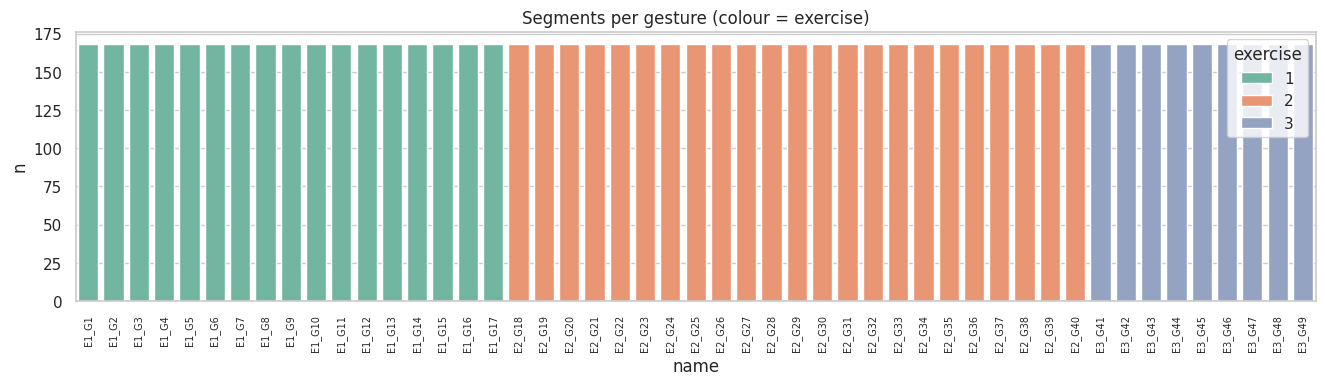

In [9]:
act_tr = seg_tr[(seg_tr.label > 0) & (seg_tr.length >= WIN)]
cls = act_tr.groupby(["exercise", "label"]).size().rename("n").reset_index()
cls["name"] = "E" + cls.exercise.astype(str) + "_G" + cls.label.astype(str)
ratio = cls.n.max() / cls.n.min()
rest = seg_tr[seg_tr.label == 0].length.sum() / seg_tr.length.sum() * 100

print(f"TRAIN subjects: imbalance {ratio:.2f}x | all subjects: {ratio_all:.2f}x  -> similar = split is representative")
print(f"{len(cls)} gesture classes | segments per class: min {cls.n.min()}, max {cls.n.max()} | imbalance {ratio:.2f}x")
print("Effect on metrics:", "balanced -> accuracy is a fair metric." if ratio < 1.5 else
      "imbalanced -> accuracy is misleading; use macro-F1 / balanced accuracy and class weights.")
print(f"Rest is {rest:.0f}% of raw samples, so it is excluded from the class counts (it would dominate accuracy).")

plt.figure(figsize=(16, 3.5))
sns.barplot(data=cls, x="name", y="n", hue="exercise", dodge=False, palette="Set2")
plt.xticks(rotation=90, fontsize=7); plt.title("Segments per gesture (colour = exercise)"); plt.show()

# E. Feature distributions (window RMS)

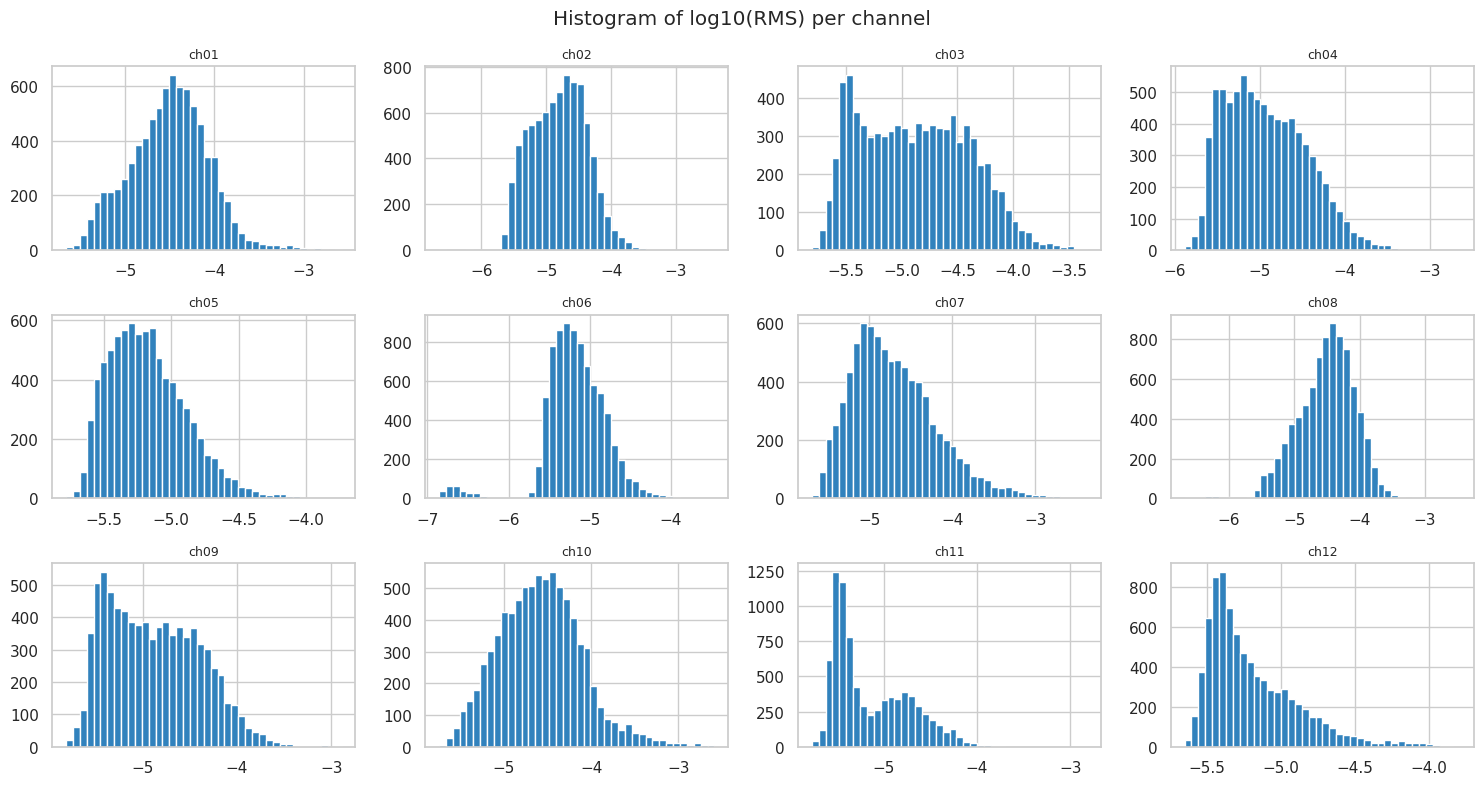

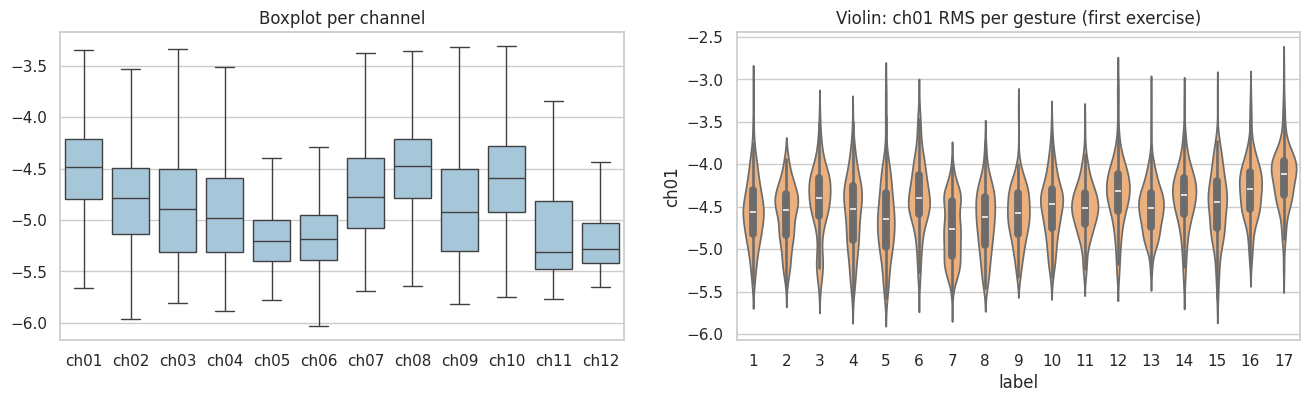

Gesture explains 15% of RMS variance on average; best channel ch11: 32%
Read it: if the violins look alike, single-channel RMS cannot separate gestures well; the pattern across channels matters.


In [10]:
logrms = np.log10(rms_tr + 1e-9)

fig, ax = plt.subplots(3, 4, figsize=(15, 8))
for a, c in zip(ax.ravel(), CH):
    a.hist(logrms[c], bins=40, color="#3182bd"); a.set_title(c, fontsize=9)
fig.suptitle("Histogram of log10(RMS) per channel"); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(16, 4))
sns.boxplot(data=logrms, ax=ax[0], showfliers=False, color="#9ecae1"); ax[0].set_title("Boxplot per channel")
e1 = win_tr.exercise == win_tr.exercise.min()
sns.violinplot(x=win_tr.label[e1], y=logrms["ch01"][e1], ax=ax[1], color="#fdae6b")
ax[1].set_title("Violin: ch01 RMS per gesture (first exercise)"); plt.show()

# do classes separate? eta^2 = share of variance explained by the gesture label (0 = none, 1 = perfect)
cls_id = win_tr.exercise.astype(str) + "_" + win_tr.label.astype(str)
eta = {c: logrms[c].groupby(cls_id).transform("mean").var() / logrms[c].var() for c in CH}
best = max(eta, key=eta.get)
print(f"Gesture explains {np.mean(list(eta.values()))*100:.0f}% of RMS variance on average; best channel {best}: {eta[best]*100:.0f}%")
print("Read it: if the violins look alike, single-channel RMS cannot separate gestures well; the pattern across channels matters.")

# E2. Class x channel pattern (one exercise)

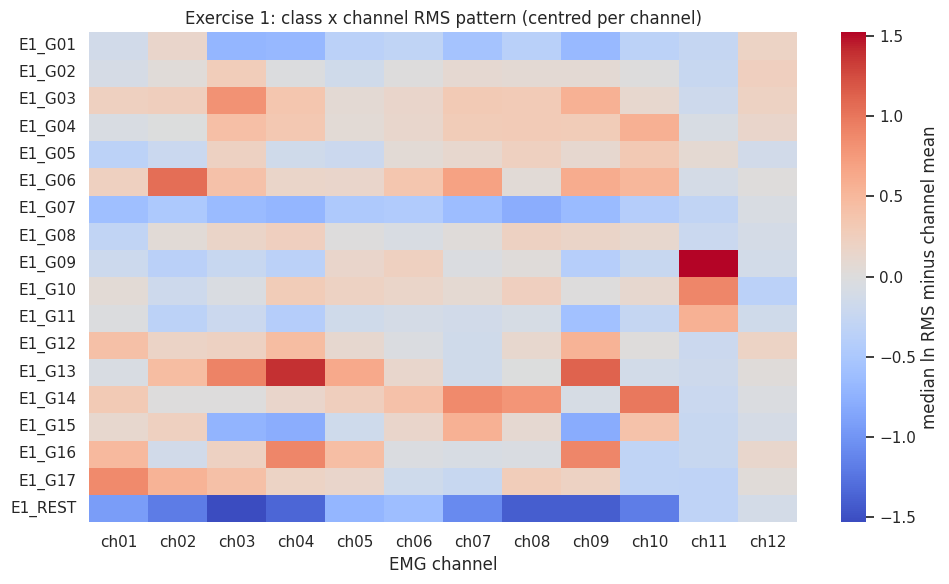

Strongest deviation: E1_REST on ch03 (-1.53 ln-units, about 4.6x vs. that channel's average)
Read it: red = channel is more active than its own average for that class, blue = less active.
Rows with different red/blue patterns = gestures can be told apart by the pattern across channels.


In [11]:
# Class x channel RMS pattern for one exercise (centred per channel)
ex = win.exercise.min()                                   # same exercise as the violin plot above

# `win` only holds active gestures, so cut REST windows from this exercise's files (train subjects only)
rest_rng = np.random.default_rng(SEED)                    # own generator -> earlier random results stay unchanged
rest_rows = []
for f in files[(files.exercise == ex) & files.subject.isin(train)].itertuples():
    m = sio.loadmat(f.path, variable_names=["emg", "restimulus", "rerepetition"])
    emg = m["emg"].astype(np.float32)
    lab, rep = m["restimulus"].ravel(), m["rerepetition"].ravel()
    cut = np.flatnonzero((np.diff(lab) != 0) | (np.diff(rep) != 0)) + 1
    for a, b in zip(np.r_[0, cut], np.r_[cut, len(lab)]):
        if lab[a] == 0 and b - a >= WIN:                  # rest segment -> 1 random window
            st = rest_rng.integers(a, b - WIN + 1)
            rest_rows.append(np.sqrt((emg[st:st + WIN] ** 2).mean(0)))

# median ln(RMS) per class and channel
use = is_train & (win.exercise == ex).values
med = np.log(rms[use] + 1e-9).groupby(win.label[use].values).median()
med.index = [f"E{ex}_G{g:02d}" for g in med.index]
med.loc[f"E{ex}_REST"] = np.log(pd.DataFrame(rest_rows, columns=CH) + 1e-9).median()

pattern = med - med.mean()                                # centre every channel (column) at 0

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(pattern, cmap="coolwarm", center=0, ax=ax, cbar_kws={"label": "median ln RMS minus channel mean"})
ax.set_title(f"Exercise {ex}: class x channel RMS pattern (centred per channel)")
ax.set_xlabel("EMG channel"); plt.yticks(rotation=0); plt.tight_layout(); plt.show()

r, c = np.unravel_index(np.abs(pattern.values).argmax(), pattern.shape)
print(f"Strongest deviation: {pattern.index[r]} on {pattern.columns[c]} ({pattern.iat[r, c]:+.2f} ln-units, "
      f"about {np.exp(abs(pattern.iat[r, c])):.1f}x vs. that channel's average)")
print("Read it: red = channel is more active than its own average for that class, blue = less active.")
print("Rows with different red/blue patterns = gestures can be told apart by the pattern across channels.")

# F. Correlation

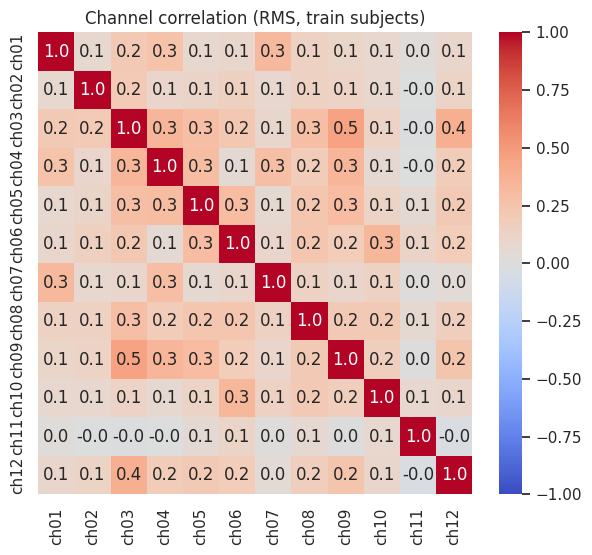

Average correlation: 0.16
Redundant channel pairs (r > 0.9): none
Top 3 pairs: ch03-ch09 (0.46), ch03-ch12 (0.39), ch04-ch09 (0.35)


In [12]:
plt.figure(figsize=(7, 6)); sns.heatmap(R, annot=True, fmt=".1f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Channel correlation (RMS, train subjects)"); plt.show()

print(f"Average correlation: {pairs.mean():.2f}")
print("Redundant channel pairs (r > 0.9):", [f"{a}-{b} ({v:.2f})" for (a, b), v in high_corr.items()] or "none")
print("Top 3 pairs:", ", ".join(f"{a}-{b} ({v:.2f})" for (a, b), v in pairs.head(3).items()))

# G. 2D / 3D view: PCA, t-SNE, UMAP

PCA variance explained: ['47%', '12%', '9%']


I0000 00:00:1794480696.139105     113 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794480716.973819     113 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


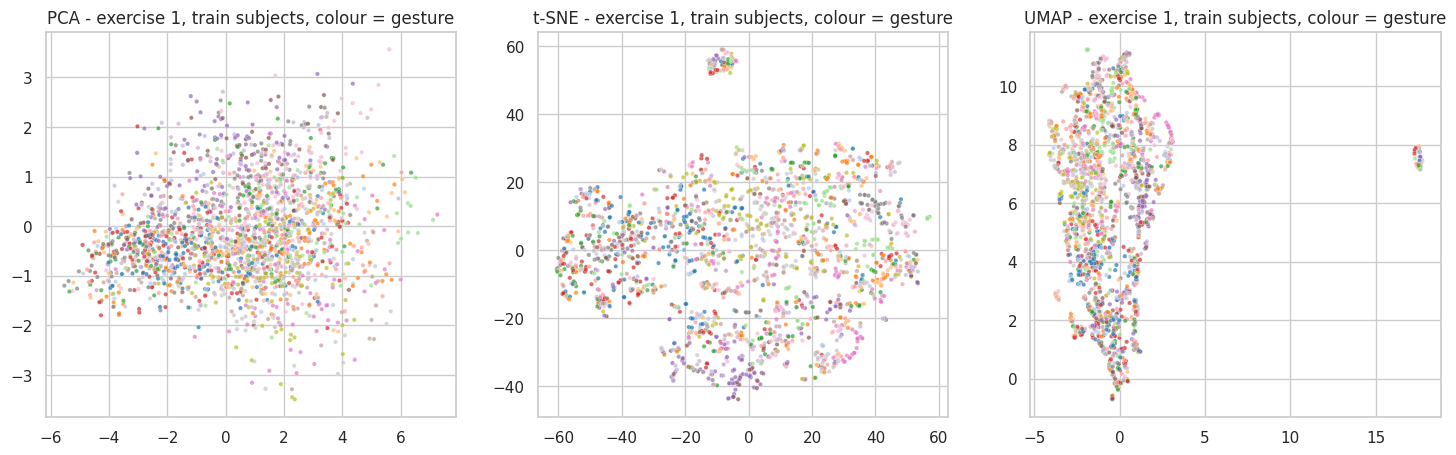

Do classes separate? (silhouette: 1 = clearly separated, 0 = overlapping, <0 = mixed)
  PCA -0.20 | t-SNE -0.20 | UMAP -0.19


In [13]:
Z = StandardScaler().fit(np.log(rms[is_train])).transform(np.log(rms))
pca = PCA(3).fit(Z[is_train]); P = pca.transform(Z)
print("PCA variance explained:", [f"{v*100:.0f}%" for v in pca.explained_variance_ratio_])

# t-SNE / UMAP on one exercise (gestures of different exercises are not comparable)
ex = win.exercise.min()
pool = np.flatnonzero((win.exercise == ex).values & is_train)      # TRAIN windows of this exercise
idx = rng.choice(pool, min(2000, len(pool)), replace=False)
y = win.label.values[idx]
T = TSNE(2, perplexity=min(30, len(idx) // 4), random_state=SEED).fit_transform(Z[idx])
try:
    import umap; U = umap.UMAP(random_state=SEED).fit_transform(Z[idx])
except ImportError:
    U = None; print("(umap-learn not installed: pip install umap-learn)")

fig, ax = plt.subplots(1, 3 if U is not None else 2, figsize=(18, 5))
for a, (E, name) in zip(ax, [(P[idx, :2], "PCA"), (T, "t-SNE"), (U, "UMAP")]):
    if E is None: continue
    sns.scatterplot(x=E[:, 0], y=E[:, 1], hue=y, palette="tab20", s=10, alpha=.7, ax=a, legend=False)
    a.set_title(f"{name} - exercise {ex}, train subjects, colour = gesture")
plt.show()

print("Do classes separate? (silhouette: 1 = clearly separated, 0 = overlapping, <0 = mixed)")
print(f"  PCA {silhouette_score(P[idx, :2], y):.2f} | t-SNE {silhouette_score(T, y):.2f}" +
      (f" | UMAP {silhouette_score(U, y):.2f}" if U is not None else ""))

# H. Interactive plots (hover, zoom, click legend)

In [14]:
d = win.assign(PC1=P[:, 0], PC2=P[:, 1], PC3=P[:, 2], gesture=win.exercise.astype(str) + "_G" + win.label.astype(str), split=split)
d = d.sample(min(4000, len(d)), random_state=SEED)

px.scatter(d, x="PC1", y="PC2", color=d.exercise.astype(str), hover_data=["subject", "gesture"],
           title="PCA 2D - colour = exercise").show()
print("Zoom in and hover to see subject and gesture.")

px.scatter(d, x="PC1", y="PC2", color="split", hover_data=["subject", "gesture"], opacity=.6,
           title="PCA 2D - colour = split (PCA fitted on train only)").show()
print("val/test points inside the train cloud = little subject shift; a separate cloud = hard cross-subject problem.")

px.scatter_3d(d, x="PC1", y="PC2", z="PC3", color=d.exercise.astype(str), opacity=.6,
              title="PCA 3D - rotate with the mouse").show()
print("A third component adds separation only if clouds that overlap in 2D split apart here.")

Zoom in and hover to see subject and gesture.


val/test points inside the train cloud = little subject shift; a separate cloud = hard cross-subject problem.


A third component adds separation only if clouds that overlap in 2D split apart here.


# Summary

In [15]:
print(f"Data       : {len(files)} files, {files.subject.nunique()} subjects, 12 channels, {len(win):,} windows")
print(f"Quality    : missing={n_bad}, duplicates={dup}, near-constant={len(near_const)}, correlated pairs>0.9={len(high_corr)}")
print(f"Classes    : {len(cls_all)} gestures, imbalance {ratio_all:.2f}x (all subjects) / {ratio:.2f}x (train)")
print(f"Split      : {len(train)}/{len(val)}/{len(test)} subjects (train/val/test), no leakage")
print(f"Separation : gesture explains {np.mean(list(eta.values()))*100:.0f}% of RMS variance (avg per channel)")
print("All statistics, class balance and feature plots above are computed on TRAIN subjects only.")

Data       : 120 files, 40 subjects, 12 channels, 11,760 windows
Quality    : missing=0, duplicates=0, near-constant=0, correlated pairs>0.9=0
Classes    : 49 gestures, imbalance 1.00x (all subjects) / 1.00x (train)
Split      : 28/4/8 subjects (train/val/test), no leakage
Separation : gesture explains 15% of RMS variance (avg per channel)
All statistics, class balance and feature plots above are computed on TRAIN subjects only.


# **Task2**

# Exercise B data prepare

In [16]:
#  CELL 1: Exercise B data (exercise 1 in DB2), same subject split as Task 1
from sklearn.preprocessing import LabelEncoder

mB = (win.exercise == 1).values
X  = np.log(rms.values[mB] + 1e-9)                 # log fixes skew
le = LabelEncoder(); y = le.fit_transform(win.label.values[mB])   # 0..16
sp = split[mB]
tr, va, te = sp == "train", sp == "val", sp == "test"

scaler = StandardScaler().fit(X[tr])               # fit on TRAIN only
Xtr, Xva, Xte = scaler.transform(X[tr]), scaler.transform(X[va]), scaler.transform(X[te])
ytr, yva, yte = y[tr], y[va], y[te]

print(f"Exercise B: {len(y)} windows, {len(le.classes_)} classes")
print(f"train {len(ytr)} | val {len(yva)} | test {len(yte)}  (subject-wise, no leakage)")
print(f"class count per class (train): min {np.bincount(ytr).min()}, max {np.bincount(ytr).max()}")
print(f"random guess accuracy = {1/len(le.classes_):.3f}")

Exercise B: 4080 windows, 17 classes
train 2856 | val 408 | test 816  (subject-wise, no leakage)
class count per class (train): min 168, max 168
random guess accuracy = 0.059


# Preprocessing checklist (computed from the data)

In [17]:
from sklearn.feature_selection import f_classif

subj_B = win.subject.values[mB]                              # subject id of every Exercise B window
s_tr, s_va, s_te = (set(subj_B[m]) for m in (tr, va, te))
cnt = np.bincount(ytr)                                       # windows per class (train)
F, pval = f_classif(Xtr, ytr)                                # ANOVA F-test per channel (train only)
weak = [c for c, p in zip(CH, pval) if p >= 0.05]

no_overlap = not (s_tr & s_va or s_tr & s_te or s_va & s_te)
finite     = bool(np.isfinite(X).all())
scaler_ok  = np.allclose(scaler.mean_, X[tr].mean(0))        # True only if the scaler saw TRAIN windows only
balanced   = cnt.max() / cnt.min() < 1.5

checks = pd.DataFrame([
    ("Subject-independent split", f"{len(s_tr)} / {len(s_va)} / {len(s_te)} subjects (train / val / test)",
     "no subject appears in two groups" if no_overlap else "LEAKAGE: fix the split", no_overlap),
    ("Missing values", f"{int((~np.isfinite(X)).sum())} non-finite values in the features",
     "no imputation needed" if finite else "impute or remove these windows", finite),
    ("Scaling", "log(RMS) + StandardScaler",
     "scaler was fitted on TRAIN windows only" if scaler_ok else "LEAKAGE: scaler saw other data", scaler_ok),
    ("Encoding", f"{len(le.classes_)} gestures mapped to labels {y.min()}..{y.max()}",
     "LabelEncoder (classes are not ordered, so no ordinal meaning is used)", True),
    ("Class imbalance", f"train windows per class: min {cnt.min()}, max {cnt.max()}",
     "balanced: no resampling or class weights needed" if balanced else "imbalanced: use class weights / macro metrics", balanced),
    ("Feature selection", f"{len(CH) - len(weak)} / {len(CH)} channels are significant (ANOVA, train only)",
     "keep all channels (each channel is a graph node)" if not weak else f"consider dropping: {weak}", True),
], columns=["Step", "Result", "Decision", "OK"])
display(checks)
print("All checks passed" if checks.OK.all() else "Some checks failed - see the table")
display(pd.DataFrame({"F_score": F, "p_value": pval}, index=CH).sort_values("F_score", ascending=False).round(4))

,Step,Result,Decision,OK
0,Subject-independent split,28 / 4 / 8 subjects (train / val / test),no subject appears in two groups,True
1,Missing values,0 non-finite values in the features,no imputation needed,True
2,Scaling,log(RMS) + StandardScaler,scaler was fitted on TRAIN windows only,True
3,Encoding,17 gestures mapped to labels 0..16,"LabelEncoder (classes are not ordered, so no o...",True
4,Class imbalance,"train windows per class: min 168, max 168",balanced: no resampling or class weights needed,True
5,Feature selection,"12 / 12 channels are significant (ANOVA, train...",keep all channels (each channel is a graph node),True


All checks passed


,F_score,p_value
ch11,62.0071,0.0
ch04,38.6083,0.0
ch09,29.0493,0.0
ch05,28.6039,0.0
ch01,26.1975,0.0
ch03,24.8289,0.0
ch02,23.1222,0.0
ch08,14.8998,0.0
ch10,11.4421,0.0
ch12,11.2773,0.0


# Baselines, metrics and training time

In [18]:
# baselines
import time
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             precision_score, recall_score, confusion_matrix)

def scores(y_true, y_pred):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "balanced_acc": balanced_accuracy_score(y_true, y_pred),
            "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
            "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
            "macro_f1": f1_score(y_true, y_pred, average="macro")}

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "SVM (RBF)":           SVC(C=10, gamma="scale"),
    "k-NN":                KNeighborsClassifier(n_neighbors=7),
    "Decision Tree":       DecisionTreeClassifier(max_depth=12, random_state=SEED),
    "Random Forest":       RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
    "Gradient Boosting":   HistGradientBoostingClassifier(max_iter=200, random_state=SEED),
    "MLP":                 MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=500, early_stopping=True, random_state=SEED),
}

rows, preds = [], {}
for name, mdl in models.items():
    t0 = time.time(); mdl.fit(Xtr, ytr); train_time = time.time() - t0
    preds[name] = mdl.predict(Xte)
    rows.append({"model": name, "val_acc": accuracy_score(yva, mdl.predict(Xva)),
                 **scores(yte, preds[name]), "train_time_s": train_time})

results = pd.DataFrame(rows).set_index("model").sort_values("macro_f1", ascending=False)
display(results.round(3))
best_name = results.index[0]
print(f"Baseline to beat: {best_name} (test macro-F1 = {results.macro_f1.iloc[0]:.3f})")

,val_acc,accuracy,balanced_acc,precision_macro,recall_macro,macro_f1,train_time_s
model,,,,,,,
Random Forest,0.240,0.196,0.196,0.202,0.196,0.182,2.623
SVM (RBF),0.245,0.189,0.189,0.203,0.189,0.180,0.596
Logistic Regression,0.289,0.194,0.194,0.196,0.194,0.176,0.155
Gradient Boosting,0.255,0.183,0.183,0.188,0.183,0.173,14.464
MLP,0.279,0.184,0.184,0.179,0.184,0.168,1.403
k-NN,0.179,0.159,0.159,0.200,0.159,0.157,0.005
Decision Tree,0.150,0.136,0.136,0.127,0.136,0.126,0.092


Baseline to beat: Random Forest (test macro-F1 = 0.182)


# Overfitting check (train vs test)

In [19]:
# does the model memorise or generalise to NEW subjects?
extra = pd.DataFrame({
    "train_acc": {n: accuracy_score(ytr, m.predict(Xtr)) for n, m in models.items()},
    "test_acc":  results.accuracy}).loc[results.index]
extra["gap"] = extra.train_acc - extra.test_acc
display(extra.round(3))

,train_acc,test_acc,gap
model,,,
Random Forest,1.000,0.196,0.804
SVM (RBF),0.707,0.189,0.519
Logistic Regression,0.301,0.194,0.107
Gradient Boosting,1.000,0.183,0.817
MLP,0.411,0.184,0.227
k-NN,0.554,0.159,0.395
Decision Tree,0.647,0.136,0.511


# Which channels are working (for all model)

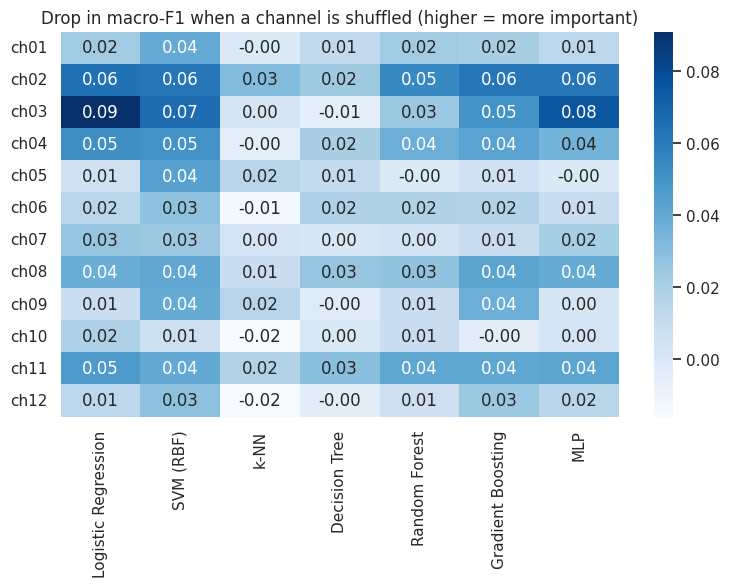

In [20]:
# channel importance (permutation, on VALIDATION set, model-agnostic)
from sklearn.inspection import permutation_importance
imp = pd.DataFrame({n: permutation_importance(m, Xva, yva, scoring="f1_macro", n_repeats=5,
                    random_state=SEED, n_jobs=-1).importances_mean for n, m in models.items()}, index=CH)
plt.figure(figsize=(9, 5)); sns.heatmap(imp, annot=True, fmt=".2f", cmap="Blues")
plt.title("Drop in macro-F1 when a channel is shuffled (higher = more important)"); plt.show()

# Which gestures are hard (for all model)

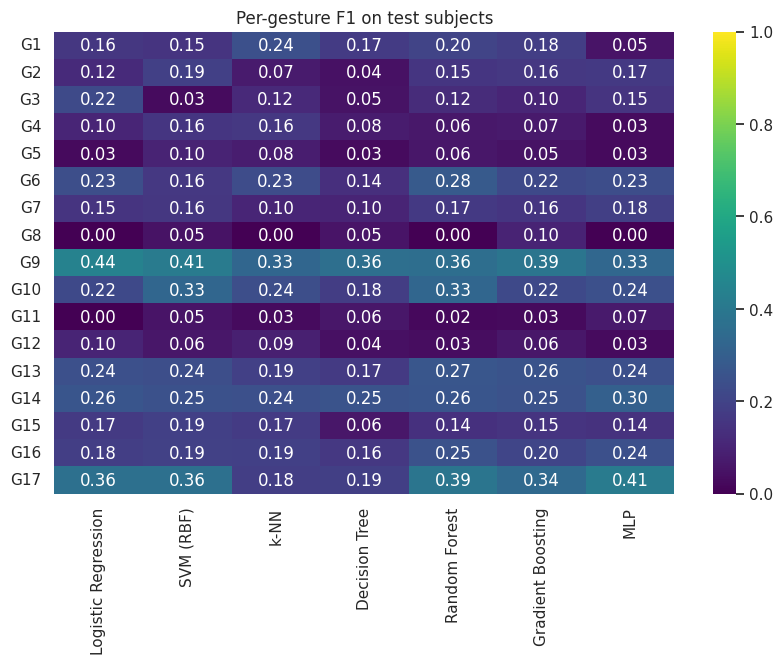

In [21]:
# per-gesture F1 for every model
f1_cls = pd.DataFrame({n: f1_score(yte, p, average=None) for n, p in preds.items()},
                      index=[f"G{c}" for c in le.classes_])
plt.figure(figsize=(10, 6)); sns.heatmap(f1_cls, annot=True, fmt=".2f", cmap="viridis", vmin=0, vmax=1)
plt.title("Per-gesture F1 on test subjects"); plt.show()

# Weight of Logistic Regression, gesture x channel

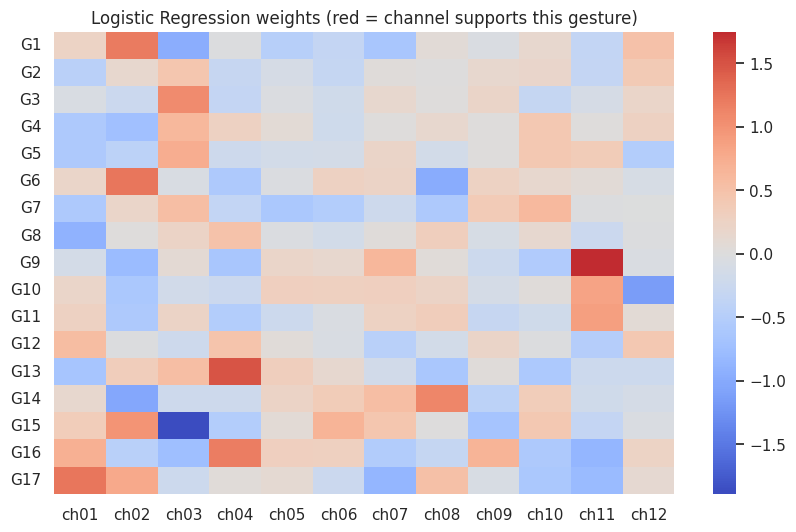

In [22]:
# which channel pushes which gesture (compare with the Task 1 class x channel heatmap)
coef = pd.DataFrame(models["Logistic Regression"].coef_, index=[f"G{c}" for c in le.classes_], columns=CH)
plt.figure(figsize=(10, 6)); sns.heatmap(coef, cmap="coolwarm", center=0)
plt.title("Logistic Regression weights (red = channel supports this gesture)"); plt.show()

# Confusion matrix of Best baseline

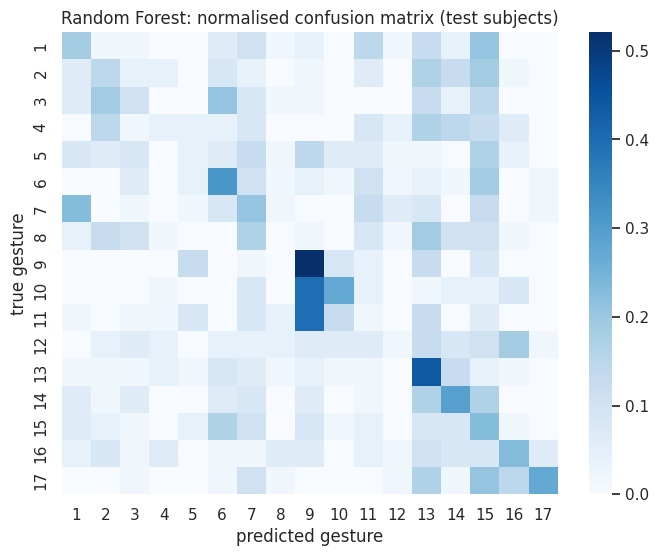

In [23]:
# confusion matrix of the best baseline
cm = confusion_matrix(yte, preds[best_name], normalize="true")
plt.figure(figsize=(8, 6))
sns.heatmap(cm, cmap="Blues", xticklabels=le.classes_, yticklabels=le.classes_)
plt.title(f"{best_name}: normalised confusion matrix (test subjects)")
plt.xlabel("predicted gesture"); plt.ylabel("true gesture"); plt.show()

# GCN on a correlation graph (Exercise B), 5 seeds

In [24]:
# GCN: graph + model + training (one place)
import torch, torch.nn as nn

# (A) graph construction - TRAIN data only
K = 3
R = np.abs(np.corrcoef(Xtr.T)); np.fill_diagonal(R, -1)
A = np.zeros((12, 12))
for i in range(12):
    nb = np.argsort(-R[i])[:K]; A[i, nb] = R[i, nb]     # top-3 neighbours, weight = |r|
A = np.maximum(A, A.T) + np.eye(12)                     # symmetric + self loops
d = A.sum(1); A_hat = A / np.sqrt(np.outer(d, d))       # D^-1/2 A D^-1/2
print("edges (without self loops):", int((A > 0).sum() - 12) // 2)

class GCN(nn.Module):
    def __init__(self, A_hat, n_cls, hid=32, p=0.2):
        super().__init__()
        self.register_buffer("A", torch.tensor(A_hat, dtype=torch.float32))
        self.l1, self.l2 = nn.Linear(1, hid), nn.Linear(hid, hid)
        self.out = nn.Linear(12 * hid, n_cls)           # flatten readout keeps electrode identity
        self.drop = nn.Dropout(p)
    def forward(self, x):                               # x: (batch, 12)
        h = x.unsqueeze(-1)                             # node feature: (batch, 12, 1)
        h = self.drop(torch.relu(self.A @ self.l1(h)))  # graph conv 1
        h = self.drop(torch.relu(self.A @ self.l2(h)))  # graph conv 2
        return self.out(h.flatten(1))

T = lambda a, dt=torch.float32: torch.tensor(a, dtype=dt)
xtr, xva, xte = T(Xtr), T(Xva), T(Xte)
ytr_t, yva_t = T(ytr, torch.long), T(yva, torch.long)

def train_gcn(seed):
    torch.manual_seed(seed)
    m = GCN(A_hat, n_cls=len(le.classes_))
    opt = torch.optim.Adam(m.parameters(), lr=5e-3, weight_decay=1e-4)
    best_val, best_state, t0 = 0, None, time.time()
    for epoch in range(300):
        m.train(); opt.zero_grad()
        nn.functional.cross_entropy(m(xtr), ytr_t).backward(); opt.step()
        m.eval()
        with torch.no_grad(): val_acc = (m(xva).argmax(1) == yva_t).float().mean().item()
        if val_acc > best_val:                          # best epoch is chosen on VALIDATION
            best_val, best_state = val_acc, {k: v.clone() for k, v in m.state_dict().items()}
    t = time.time() - t0
    m.load_state_dict(best_state); m.eval()
    with torch.no_grad(): p = m(xte).argmax(1).numpy()  # TEST is used once per seed
    return best_val, p, t

runs, gcn_preds = [], []
for seed in range(5):
    v, p, t = train_gcn(seed)
    gcn_preds.append(p)
    runs.append({"seed": seed, "val_acc": v, **scores(yte, p), "train_time_s": t})
runs = pd.DataFrame(runs).set_index("seed")
preds["GCN"] = gcn_preds[0]                      # seed 0, used for the per-gesture heatmap
display(runs.round(3))
print(f"GCN macro-F1: mean {runs.macro_f1.mean():.3f}, std {runs.macro_f1.std():.3f}")

edges (without self loops): 26


,val_acc,accuracy,balanced_acc,precision_macro,recall_macro,macro_f1,train_time_s
seed,,,,,,,
0,0.216,0.188,0.188,0.188,0.188,0.174,15.588
1,0.218,0.190,0.190,0.179,0.190,0.170,15.439
2,0.218,0.186,0.186,0.180,0.186,0.168,15.363
3,0.218,0.185,0.185,0.187,0.185,0.171,15.349
4,0.218,0.180,0.180,0.188,0.180,0.165,15.316


GCN macro-F1: mean 0.170, std 0.003


# Per-gesture comparison (baselines + GCN)

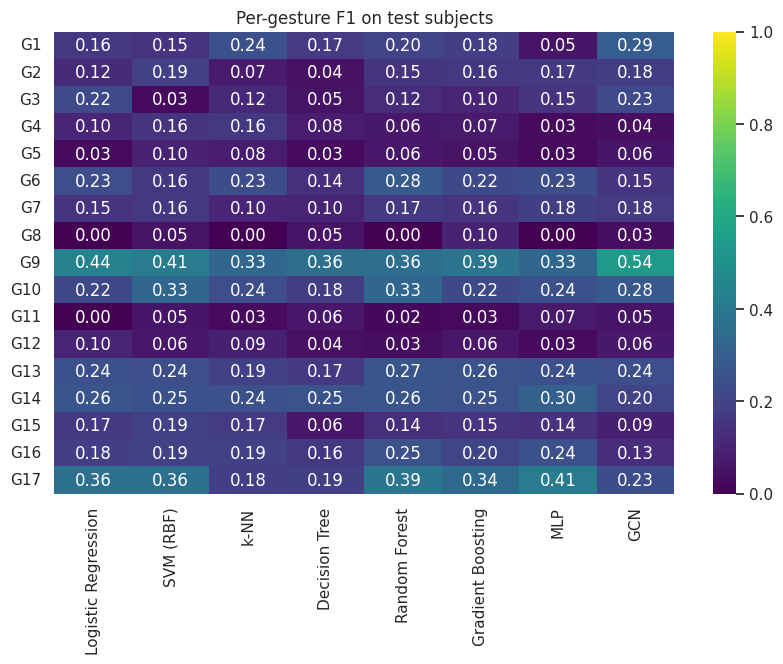

In [25]:
# Per-gesture comparison (baselines + GCN)
f1_cls = pd.DataFrame({n: f1_score(yte, p, average=None) for n, p in preds.items()},
                      index=[f"G{c}" for c in le.classes_])
plt.figure(figsize=(10, 6)); sns.heatmap(f1_cls, annot=True, fmt=".2f", cmap="viridis", vmin=0, vmax=1)
plt.title("Per-gesture F1 on test subjects"); plt.show()

# First results: GCN vs baselines

In [26]:
base = results.drop(index="GCN (ours)", errors="ignore")         # baselines only
final = base.copy()
final.loc["GCN (mean of 5 seeds)"] = runs.mean()
display(final.sort_values("macro_f1", ascending=False).round(3))

best_base, best_f1 = base.macro_f1.idxmax(), base.macro_f1.max()
g_mean, g_std = runs.macro_f1.mean(), runs.macro_f1.std()
print(f"Baseline to beat: {best_base} (test macro-F1 = {best_f1:.3f})")
print(f"GCN: {g_mean:.3f} +- {g_std:.3f}")
if g_mean - g_std > best_f1:   print("Verdict: the GCN is better than the best baseline.")
elif g_mean + g_std < best_f1: print("Verdict: the GCN is worse than the best baseline.")
else:                          print("Verdict: no clear difference (the gap is inside the seed noise).")
print(f"Random guess = {1/len(le.classes_):.3f}. The test set has only {len(s_te)} subjects, so gaps of 1-2 points are not reliable.")

,val_acc,accuracy,balanced_acc,precision_macro,recall_macro,macro_f1,train_time_s
model,,,,,,,
Random Forest,0.240,0.196,0.196,0.202,0.196,0.182,2.623
SVM (RBF),0.245,0.189,0.189,0.203,0.189,0.180,0.596
Logistic Regression,0.289,0.194,0.194,0.196,0.194,0.176,0.155
Gradient Boosting,0.255,0.183,0.183,0.188,0.183,0.173,14.464
GCN (mean of 5 seeds),0.218,0.186,0.186,0.185,0.186,0.170,15.411
MLP,0.279,0.184,0.184,0.179,0.184,0.168,1.403
k-NN,0.179,0.159,0.159,0.200,0.159,0.157,0.005
Decision Tree,0.150,0.136,0.136,0.127,0.136,0.126,0.092


Baseline to beat: Random Forest (test macro-F1 = 0.182)
GCN: 0.170 +- 0.003
Verdict: the GCN is worse than the best baseline.
Random guess = 0.059. The test set has only 8 subjects, so gaps of 1-2 points are not reliable.


# GNN proposal
## (A) Graph construction

| Item | Our choice |
|---|---|
| Graph | one small graph for every 200 ms window |
| Nodes | the 12 sEMG electrodes (ch01 ... ch12) |
| Node feature | log RMS of that electrode, standardised with the train scaler (1 value per node) |
| Edges | each electrode is connected to its 3 most correlated electrodes (top-3), graph made symmetric, self-loops added |
| Edge weight | absolute Pearson correlation \|r\| between two channels, computed on TRAIN windows only |
| Normalisation | A_hat = D^-1/2 (A + I) D^-1/2 |

**Why it fits:** a gesture activates a pattern of forearm muscles, not a single channel. Electrodes close to the same muscle give correlated signals,
so connecting them lets the model combine information from related electrodes while still treating every electrode as its own node.
The graph is the same for all samples and is built from training data only, so there is no leakage.

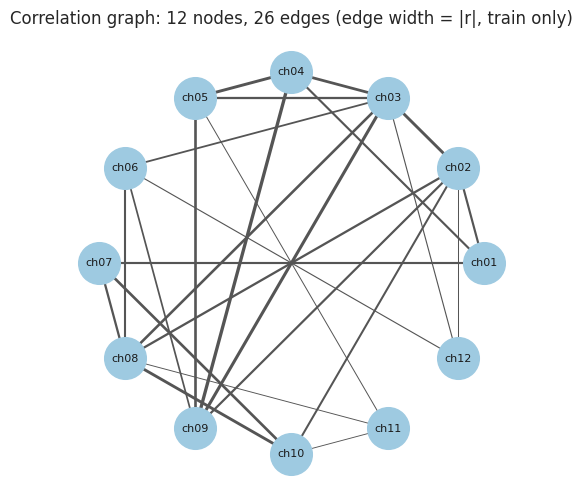

In [27]:
# draw the graph that the GCN uses (A comes from the GCN cell above)
A_plain = A - np.eye(12)                                         # remove self-loops for drawing
G = nx.relabel_nodes(nx.from_numpy_array(A_plain), {i: CH[i] for i in range(12)})
w = [G[u][v]["weight"] for u, v in G.edges]
plt.figure(figsize=(6, 6))
nx.draw_networkx(G, nx.circular_layout(G), node_color="#9ecae1", node_size=900, font_size=8,
                 width=[3 * x for x in w], edge_color="#555")
plt.title(f"Correlation graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges (edge width = |r|, train only)")
plt.axis("off"); plt.show()

## (B) Architecture diagram

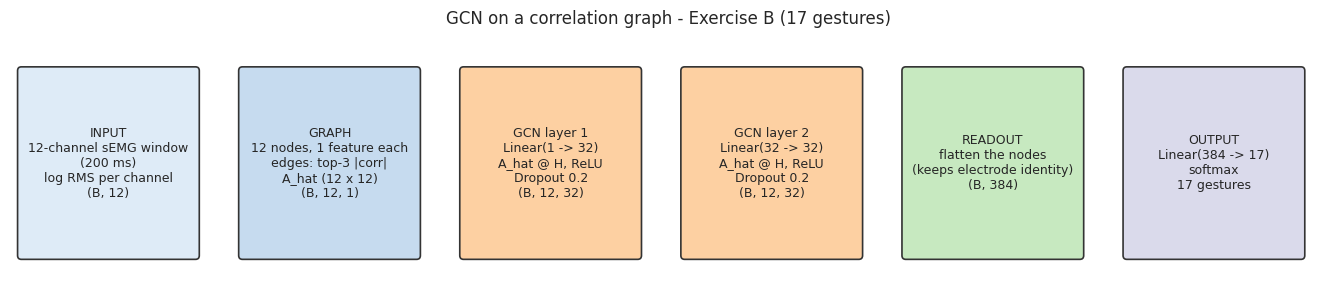

In [28]:
from matplotlib.patches import FancyBboxPatch

steps = [
    ("INPUT\n12-channel sEMG window\n(200 ms)\nlog RMS per channel\n(B, 12)", "#deebf7"),
    ("GRAPH\n12 nodes, 1 feature each\nedges: top-3 |corr|\nA_hat (12 x 12)\n(B, 12, 1)", "#c6dbef"),
    ("GCN layer 1\nLinear(1 -> 32)\nA_hat @ H, ReLU\nDropout 0.2\n(B, 12, 32)", "#fdd0a2"),
    ("GCN layer 2\nLinear(32 -> 32)\nA_hat @ H, ReLU\nDropout 0.2\n(B, 12, 32)", "#fdd0a2"),
    ("READOUT\nflatten the nodes\n(keeps electrode identity)\n(B, 384)", "#c7e9c0"),
    ("OUTPUT\nLinear(384 -> 17)\nsoftmax\n17 gestures", "#dadaeb"),
]
fig, ax = plt.subplots(figsize=(17, 3.4)); ax.axis("off"); ax.set_xlim(0, 17.4); ax.set_ylim(0, 3.4)
bw, gap = 2.3, 0.62
for k, (txt, col) in enumerate(steps):
    x = 0.15 + k * (bw + gap)
    ax.add_patch(FancyBboxPatch((x, 0.5), bw, 2.4, boxstyle="round,pad=0.05", fc=col, ec="#333", lw=1.2))
    ax.text(x + bw / 2, 1.7, txt, ha="center", va="center", fontsize=9)
    if k < len(steps) - 1:
        ax.annotate("", xy=(x + bw + gap - 0.05, 1.7), xytext=(x + bw + 0.05, 1.7), arrowprops=dict(arrowstyle="->", lw=1.8))
ax.set_title("GCN on a correlation graph - Exercise B (17 gestures)", fontsize=12)
plt.show()

## (C) How it works, in plain words, and the settings

Each 200 ms EMG window becomes a small graph with 12 nodes, one per electrode. A node only carries one number: how active the muscle under that electrode is (log RMS).
In every GCN layer a node first transforms its own value and then mixes it with the values of its connected neighbours, weighted by their correlation.
Two layers mean that information can travel two steps through the graph. At the end we do not average the nodes, because that would hide which electrode was active.
Instead we keep all 12 node vectors side by side (flatten) and a final linear layer gives one score per gesture. The model is trained with cross-entropy,
and the epoch with the best validation accuracy is the one we test.


In [29]:
settings = pd.Series({
    "Task": "17-class gesture recognition, Exercise B, subject-independent",
    "Nodes / node feature": "12 electrodes / log RMS (1 value per node)",
    "Graph": "top-3 |corr| neighbours, symmetric, self-loops, D^-1/2 A D^-1/2, built from train data",
    "GCN layers": "2 x (Linear -> A_hat @ H -> ReLU -> Dropout)",
    "Hidden size / dropout": "32 / 0.2",
    "Readout": "flatten (12 x 32 = 384) -> Linear(384, 17)",
    "Loss / optimiser": "cross-entropy / Adam (lr 5e-3, weight decay 1e-4)",
    "Epochs / batch": "300 / full batch",
    "Model selection": "epoch with the best validation accuracy",
    "Seeds": "5 (0 to 4), mean and std reported",
}, name="setting").to_frame()
display(settings)

,setting
Task,"17-class gesture recognition, Exercise B, subj..."
Nodes / node feature,12 electrodes / log RMS (1 value per node)
Graph,"top-3 |corr| neighbours, symmetric, self-loops..."
GCN layers,2 x (Linear -> A_hat @ H -> ReLU -> Dropout)
Hidden size / dropout,32 / 0.2
Readout,"flatten (12 x 32 = 384) -> Linear(384, 17)"
Loss / optimiser,"cross-entropy / Adam (lr 5e-3, weight decay 1e-4)"
Epochs / batch,300 / full batch
Model selection,epoch with the best validation accuracy
Seeds,"5 (0 to 4), mean and std reported"


# Conclusion

- **Baseline to beat:** Random Forest, test macro-F1 = 0.182 (random guess = 0.059).
- **GCN result:** macro-F1 = 0.170 ± 0.003 over 5 seeds. It is slightly worse than the best baseline and similar to Gradient Boosting (0.173) and MLP (0.168). With only 8 test subjects, gaps of 1-2 points are not reliable.
- **Overfitting:** Random Forest and Gradient Boosting reach 100% train accuracy but only about 19% on new subjects, so the main difficulty is subject-to-subject variation, not model capacity. Logistic Regression has the smallest gap (0.107).
- **Channels:** ch11, ch04 and ch09 are the most informative channels (ANOVA F-score), so these are the key nodes of the graph.
- **Why the GCN does not win yet:** only one feature per node (log RMS), one window per repetition, and a graph built from weak correlations (mean r = 0.16). The graph adds little when the node feature is so small.
- **Next steps:** more node features (MAV, WL, ZC), several windows per repetition, per-subject normalisation, a ring-based or learned adjacency, and comparing graph types (Task 3).